# Test 1: can changing a few team habits win us more rounds?

**Status: stopped early at 12 of 20 matches (2026-11-17).** Pre-registered plan, rules and full write-up: [`experiments/test1_team_habits.md`](../../experiments/test1_team_habits.md).

**Why these habits** (from exploration notebooks 02–04):
- Losing the first fight untraded happens in 37% of gun rounds, and we win only ~25% of those. Only 23% of our first deaths get traded.
- We throw ~20–25% fewer nades before the first fight than our opponents.
- On CT I'm worth the most playing back, and negative when I'm the furthest forward.

| | Habit | Who |
|---|---|---|
| **H1** (primary) | Trade the first fight | whole team |
| **H2** | One more nade before the first fight | me + whoever I can get on board |
| **H3** | Me: play back and support on CT | me |

**Success rule** (locked before playing): a habit "worked" if the 95% bootstrap interval for the change (resampling whole matches) is entirely on the right side of zero, **and** its control metric (what opponents did in the same matches) didn't move the same way. Round win rate is report-only: ~100 matches would be needed to detect a 5-point change.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())  # project root
sys.path.insert(0, str(ROOT / "src" / "experiments"))
import test1_team_habits as t1  # the scorer written before the test started

FIG = ROOT / "figures"
START = pd.Timestamp("2026-11-09", tz="Asia/Singapore")   # locked start
END = pd.Timestamp("2026-11-17", tz="Asia/Singapore")     # stopped early; later matches belong to test 3

rf, kills, pr, pos, nades = t1.load()
r = t1.per_round(rf, kills, pr, pos, nades)
base = r[r["started_at_local"] < START]
exp = r[(r["started_at_local"] >= START) & (r["started_at_local"] < END)]
print(f"baseline:   {base['match_id'].nunique()} matches, {len(base)} gun rounds")
print(f"experiment: {exp['match_id'].nunique()} matches, {len(exp)} gun rounds")

baseline:   61 matches, 1234 gun rounds
experiment: 12 matches, 224 gun rounds


## Results, scored exactly as locked

In [2]:
rng = np.random.default_rng(0)
rows = []
for name, (col, side, note) in t1.METRICS.items():
    a, b = t1.subset(base, side), t1.subset(exp, side)
    lo, hi = t1.boot_diff(a, b, col, rng)
    rows.append({"metric": name, "baseline": a[col].astype(float).mean(), "experiment": b[col].astype(float).mean(),
                 "ci_low": lo, "ci_high": hi, "note": note})
res = pd.DataFrame(rows).set_index("metric")
res["change"] = res["experiment"] - res["baseline"]
res = res[["baseline", "experiment", "change", "ci_low", "ci_high", "note"]]
res.round(3)

,baseline,experiment,change,ci_low,ci_high,note
metric,,,,,,
H1 first death traded (T),0.261,0.275,0.015,-0.098,0.123,share of our first deaths that get traded
H1 first death traded (CT),0.189,0.073,-0.116,-0.191,-0.038,
H1 first death traded (both),0.226,0.200,-0.026,-0.090,0.042,PRIMARY
H1 control: their first death traded,0.193,0.211,0.017,-0.063,0.086,should NOT move
H2 our nades before first kill (T),2.274,2.057,-0.217,-0.704,0.315,per gun round
H2 our nades before first kill (CT),2.814,2.992,0.178,-0.541,0.874,
H2 my nades before first kill (T),0.797,0.934,0.137,-0.072,0.384,me as util lead
H2 control: their nades before first kill,3.399,3.665,0.266,-0.324,0.769,should NOT move
H3 me furthest forward at 0:15 (CT),0.121,0.092,-0.029,-0.100,0.048,share of my CT rounds


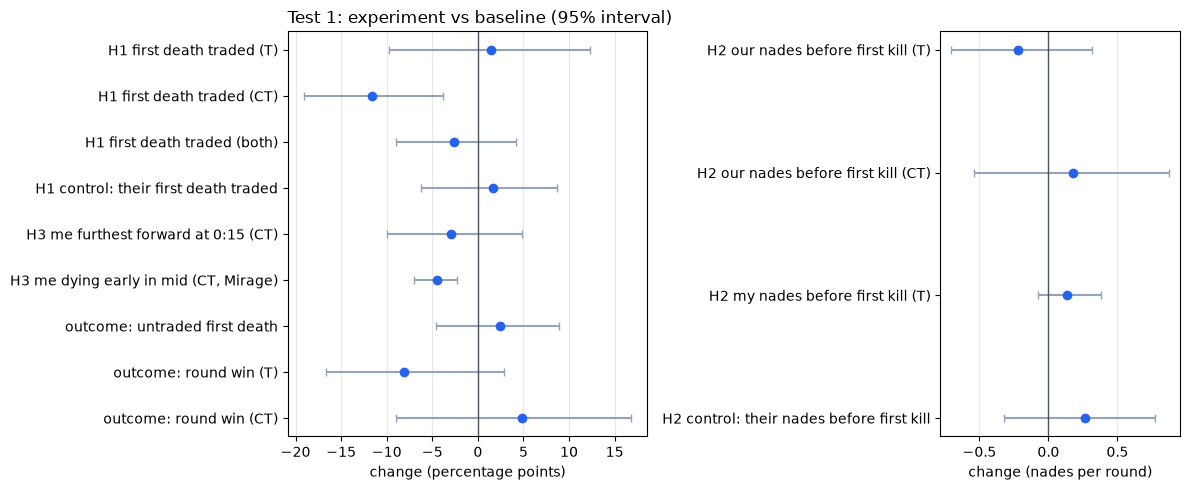

In [3]:
# Each change with its 95% interval. Shares are shown in percentage points, nade counts per round.
is_share = ~res.index.str.contains("nades")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [3, 2]})
for ax, mask, scale, unit in [(axes[0], is_share, 100, "change (percentage points)"),
                              (axes[1], ~is_share, 1, "change (nades per round)")]:
    d = res[mask].iloc[::-1]
    y = np.arange(len(d))
    ax.errorbar(d["change"] * scale, y, xerr=[(d["change"] - d["ci_low"]) * scale, (d["ci_high"] - d["change"]) * scale],
                fmt="o", color="#2563eb", ecolor="#94a3b8", capsize=3)
    ax.axvline(0, color="#475569", lw=1)
    ax.set_yticks(y, d.index)
    ax.set_xlabel(unit)
    ax.grid(axis="x", alpha=0.3)
axes[0].set_title("Test 1: experiment vs baseline (95% interval)", loc="left")
fig.tight_layout()
fig.savefig(FIG / "exp01_results.png", dpi=150, bbox_inches="tight")
plt.show()

## What it says

**I stopped this experiment at 12 of 20 matches because the habits never got done.** Pairs didn't happen and there were no coordinated CT pushes. I couldn't make everyone play a certain way, since not everyone is willing to listen. With no team habits in place, 8 more matches would only measure the same thing again. That call was made after seeing the week 1 numbers, and it's written down so it's visible.

- **The primary metric (first deaths traded) is flat, and CT trades actually got worse.** The only interval clear of zero in the right direction is my early mid deaths on Mirage CT (0 in 48 rounds), which the plan marked as too rare to test, so it's reported, not claimed.
- **The controls are flat too**, so it isn't the lobbies changing either.
- **The test was never really run**: H1 and H3 weren't done, so this says nothing about whether *trading more* would help. It only shows that telling five friends to trade more doesn't make it happen.
- CT trades likely got worse partly because I played for survival and was further from where teammates died (exploratory, see `docs/JOURNAL.md`, 2026-11-17).

**What I learned:** a habit experiment has to target something I control myself. Test 2 (withdrawn before any match) and test 3 (`experiments/test3_ct_rushes.md`, running) only depend on me.